
# Online Course Recommendation System — Data Cleaning & EDA
**Project:** P683 — Online Course Recommendation System Dataset V2

**Milestone:** Data Cleaning + EDA

This notebook covers:
1. Loading and first look at the data
2. Data cleaning (missing values, duplicates, range checks, outliers, consistency checks)
3. Exploratory Data Analysis (univariate, bivariate, correlation)
4. Saving the cleaned dataset for the next milestone (Model Building)



## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)


## 2. Load the Dataset


The previous cell encountered a `FileNotFoundError` because the Excel file `online_course_recommendation_v2.xlsx` could not be found at `/content/online_course_recommendation_v2.xlsx`.

Please ensure the file is uploaded to your Colab environment or update the `FILE_PATH` to its correct location.

In [ ]:
# You can upload the file by running this cell and selecting your file.
# Make sure to upload 'online_course_recommendation_v2.xlsx'.
from google.colab import files

# Uncomment the following line and run the cell to upload your file
# files.upload()

# After uploading, if the file is not in /content/, you might need to move it
# or update the FILE_PATH in the next cell accordingly.

In [ ]:
# Update this path if your file is located elsewhere
FILE_PATH = "/content/online_course_recommendation_v2.xlsx"

df = pd.read_excel(FILE_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (100000, 14)


,user_id,course_id,course_name,instructor,course_duration_hours,certification_offered,difficulty_level,rating,enrollment_numbers,course_price,feedback_score,study_material_available,time_spent_hours,previous_courses_taken
0,15796,9366,Python for Beginners,Emma Harris,39.1,Yes,Beginner,5.0,21600,317.50,0.797,Yes,17.60,4
1,861,1928,Cybersecurity for Professionals,Alexander Young,36.3,Yes,Beginner,4.3,15379,40.99,0.770,Yes,28.97,9
2,38159,9541,DevOps and Continuous Deployment,Dr. Mia Walker,13.4,Yes,Beginner,3.9,6431,380.81,0.772,Yes,52.44,4
3,44733,3708,Project Management Fundamentals,Benjamin Lewis,58.3,Yes,Beginner,3.1,48245,342.80,0.969,No,22.29,6
4,11285,3361,Ethical Hacking Masterclass,Daniel White,30.8,Yes,Beginner,2.8,34556,381.01,0.555,Yes,22.01,5



## 3. First Look at the Data

Before cleaning anything, we check the structure: column names, data types,
and basic statistics. This tells us what kind of cleaning is actually needed
instead of guessing.


In [ ]:
df.info()

In [ ]:
df.describe(include='all').T

In [ ]:
# Column-wise data types — useful to confirm categorical vs numeric vs id columns
df.dtypes


## 4. Missing Values

Check every column for nulls. Even if a column shows 0 missing values,
it's worth checking for "hidden" missing values like empty strings or
placeholder text (e.g. "NA", "Unknown", "-").


In [ ]:
# Standard missing value check
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df[missing_df.missing_count > 0].sort_values('missing_count', ascending=False)

,missing_count,missing_pct


In [ ]:
# Hidden missing values disguised as strings (common in real-world data)
placeholder_values = ['NA', 'N/A', 'na', 'n/a', 'null', 'NULL', '-', '', ' ', 'Unknown', 'unknown']
string_cols = [c for c in df.columns if df[c].dtype == object or df[c].dtype.name == 'str']

for col in string_cols:
    found = df[col].isin(placeholder_values).sum()
    if found > 0:
        print(f"{col}: {found} placeholder/hidden-missing values found")
print("Check complete — if nothing printed above, no hidden missing values were found.")

Check complete — if nothing printed above, no hidden missing values were found.



**Cleaning action:** If missing values are found, handle them based on column type:
- Numeric columns → impute with median (robust to outliers) or drop rows if very few
- Categorical columns → impute with mode, or a new category like `'Unknown'`
- If a column has a very high % missing (e.g. >40%), consider dropping the column

Uncomment and adapt the cell below if your run of the dataset has missing values.


In [ ]:
# Example imputation pattern (uncomment & adapt to the columns that actually need it)

# numeric_cols = ['course_duration_hours', 'rating', 'enrollment_numbers', 'course_price',
#                  'feedback_score', 'time_spent_hours', 'previous_courses_taken']
# for col in numeric_cols:
#     if df[col].isnull().sum() > 0:
#         df[col] = df[col].fillna(df[col].median())

# categorical_cols = ['certification_offered', 'difficulty_level', 'study_material_available']
# for col in categorical_cols:
#     if df[col].isnull().sum() > 0:
#         df[col] = df[col].fillna(df[col].mode()[0])


## 5. Duplicate Records

Two checks:
1. Fully duplicated rows (every column identical)
2. Duplicate `(user_id, course_id)` pairs — the same learner enrolled in the
   same course more than once. Depending on what the data is supposed to
   represent, this may be a genuine repeat enrollment or a data entry error.


In [ ]:
full_dupes = df.duplicated().sum()
print(f"Fully duplicated rows: {full_dupes}")

if full_dupes > 0:
    df = df.drop_duplicates()
    print(f"Dropped. New shape: {df.shape}")

Fully duplicated rows: 0


In [ ]:
full_dupes = df.duplicated().sum()
print(f"Fully duplicated rows: {full_dupes}")

if full_dupes > 0:
    df = df.drop_duplicates()
    print(f"Dropped. New shape: {df.shape}")

Fully duplicated rows: 0


In [ ]:
full_dupes = df.duplicated().sum()
print(f"Fully duplicated rows: {full_dupes}")

if full_dupes > 0:
    df = df.drop_duplicates()
    print(f"Dropped. New shape: {df.shape}")

Fully duplicated rows: 0



**Cleaning action:** For a recommendation system, a user normally appears once
per course (one rating/interaction per user-course pair). We keep the **first**
occurrence and drop the rest — adjust this rule if your use case treats repeat
enrollments as meaningful (e.g. retakes).


In [ ]:
df = df.drop_duplicates(subset=['user_id', 'course_id'], keep='first')
print("Shape after removing duplicate user-course pairs:", df.shape)


Shape after removing duplicate user-course pairs: (99995, 14)



## 6. Range & Consistency Checks

The business document specifies expected ranges for several columns. We
validate that the data actually respects them, and check for negative
values where they shouldn't exist.


In [ ]:
range_rules = {
    'course_duration_hours': (5.0, 100.0),
    'rating': (1.0, 5.0),
    'course_price': (20.0, 500.0),
    'feedback_score': (0.0, 1.0),
    'time_spent_hours': (1.0, 100.0),
}

for col, (low, high) in range_rules.items():
    out_of_range = df[(df[col] < low) | (df[col] > high)]
    print(f"{col}: {len(out_of_range)} rows outside [{low}, {high}]")

course_duration_hours: 0 rows outside [5.0, 100.0]
rating: 0 rows outside [1.0, 5.0]
course_price: 0 rows outside [20.0, 500.0]
feedback_score: 0 rows outside [0.0, 1.0]
time_spent_hours: 0 rows outside [1.0, 100.0]


In [ ]:
# Columns that should never be negative
non_negative_cols = ['enrollment_numbers', 'previous_courses_taken', 'user_id', 'course_id']
for col in non_negative_cols:
    neg = (df[col] < 0).sum()
    print(f"{col}: {neg} negative values")

enrollment_numbers: 0 negative values
previous_courses_taken: 0 negative values
user_id: 0 negative values
course_id: 0 negative values


In [ ]:
# Categorical values should match exactly what's documented (Yes/No, Beginner/Intermediate/Advanced)
for col in ['certification_offered', 'study_material_available']:
    print(col, '->', sorted(df[col].unique()))

print('difficulty_level ->', sorted(df['difficulty_level'].unique()))

certification_offered -> ['No', 'Yes']
study_material_available -> ['No', 'Yes']
difficulty_level -> ['Advanced', 'Beginner', 'Intermediate']


In [ ]:
# Consistency check: does each course_name always map to the same instructor & difficulty?
# (a course shouldn't randomly change instructor across rows)
inconsistent_instructor = df.groupby('course_name')['instructor'].nunique()
inconsistent_instructor = inconsistent_instructor[inconsistent_instructor > 1]
print("Courses with more than one instructor on record:", len(inconsistent_instructor))
inconsistent_instructor

Courses with more than one instructor on record: 20


,instructor
course_name,
AI for Business Leaders,20
Advanced Machine Learning,20
Blockchain and Decentralized Applications,20
Cloud Computing Essentials,20
Cybersecurity for Professionals,20
Data Visualization with Tableau,20
DevOps and Continuous Deployment,20
Ethical Hacking Masterclass,20
Fitness and Nutrition Coaching,20


In [ ]:
# Whitespace / casing issues in text columns (e.g. "Yes " vs "Yes", "yes" vs "Yes")
text_cols = ['course_name', 'instructor', 'certification_offered', 'difficulty_level', 'study_material_available']
for col in text_cols:
    has_ws = (df[col].astype(str) != df[col].astype(str).str.strip()).sum()
    print(f"{col}: {has_ws} values with leading/trailing whitespace")

# Standardize just in case
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

course_name: 0 values with leading/trailing whitespace
instructor: 0 values with leading/trailing whitespace
certification_offered: 0 values with leading/trailing whitespace
difficulty_level: 0 values with leading/trailing whitespace
study_material_available: 0 values with leading/trailing whitespace



## 7. Outlier Detection (IQR Method)

For numeric columns without a hard documented range (e.g. `enrollment_numbers`,
`previous_courses_taken`), we use the IQR (Interquartile Range) method to flag
statistical outliers. We flag them here rather than blindly deleting them —
outliers in enrollment counts may be genuinely popular courses, not errors.


In [ ]:
numeric_cols = ['course_duration_hours', 'rating', 'enrollment_numbers', 'course_price',
                 'feedback_score', 'time_spent_hours', 'previous_courses_taken']

def iqr_outlier_summary(data, cols):
    rows = []
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outliers = data[(data[col] < lower) | (data[col] > upper)]
        rows.append({
            'column': col, 'lower_bound': round(lower, 2), 'upper_bound': round(upper, 2),
            'outlier_count': len(outliers), 'outlier_pct': round(100 * len(outliers) / len(data), 2)
        })
    return pd.DataFrame(rows)

outlier_summary = iqr_outlier_summary(df, numeric_cols)
outlier_summary

,column,lower_bound,upper_bound,outlier_count,outlier_pct
0,course_duration_hours,-42.65,147.35,0,0.00
1,rating,2.00,6.00,529,0.53
2,enrollment_numbers,-24822.75,74927.25,0,0.00
3,course_price,-222.31,744.12,0,0.00
4,feedback_score,0.35,1.15,377,0.38
5,time_spent_hours,-20.37,60.35,342,0.34
6,previous_courses_taken,-1.50,10.50,1373,1.37


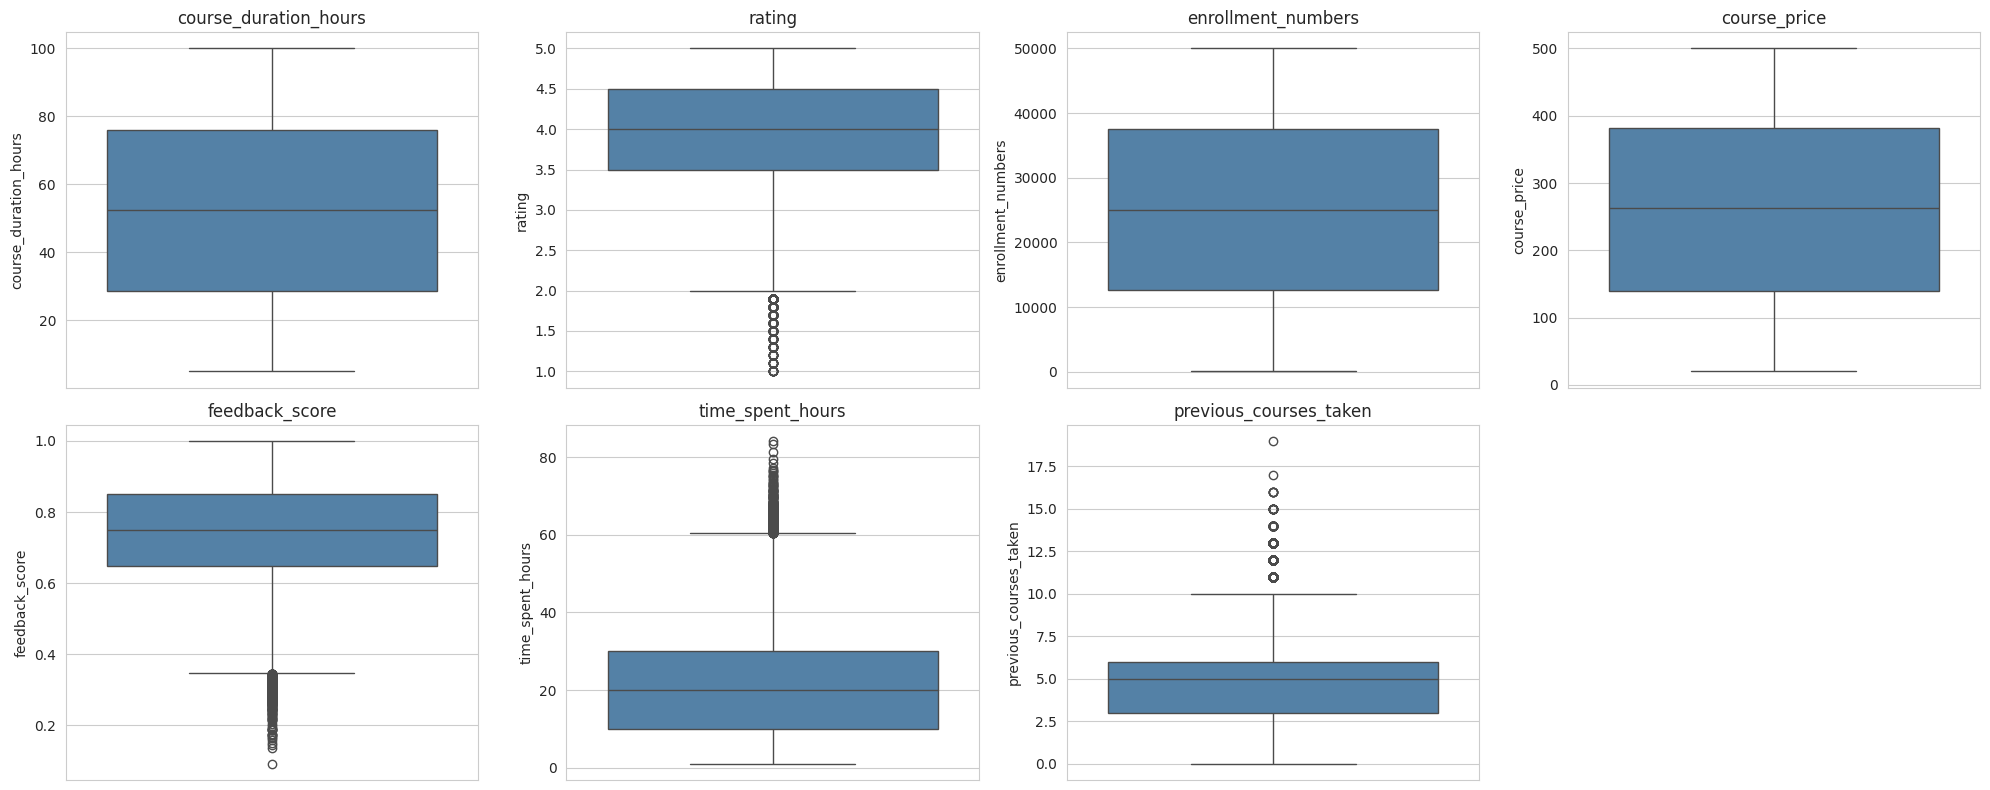

In [ ]:
# Visualize outliers with boxplots
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='steelblue')
    axes[i].set_title(col)
axes[-1].axis('off')
plt.tight_layout()
plt.show()


**Cleaning action:** Since `enrollment_numbers` and similar columns can be
legitimately skewed (a few very popular courses), we **cap (winsorize)** rather
than delete outliers, preserving row count for the recommendation model. Adjust
this if your assignment asks for outlier removal instead.


In [ ]:
# Capping (winsorizing) instead of deleting — keeps all rows for the recommender system
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    df[col] = df[col].clip(lower=lower, upper=upper)

print("Outliers capped. Re-checking:")
iqr_outlier_summary(df, numeric_cols)

Outliers capped. Re-checking:


,column,lower_bound,upper_bound,outlier_count,outlier_pct
0,course_duration_hours,-42.65,147.35,0,0.0
1,rating,2.00,6.00,0,0.0
2,enrollment_numbers,-24822.75,74927.25,0,0.0
3,course_price,-222.31,744.12,0,0.0
4,feedback_score,0.35,1.15,0,0.0
5,time_spent_hours,-20.37,60.35,0,0.0
6,previous_courses_taken,-1.50,10.50,0,0.0



## 8. Save the Cleaned Dataset


In [ ]:
df.to_csv("course_recommendation_cleaned.csv", index=False)
print("Cleaned dataset saved as 'course_recommendation_cleaned.csv'")
print("Final shape:", df.shape)

Cleaned dataset saved as 'course_recommendation_cleaned.csv'
Final shape: (99995, 14)



## 9. Exploratory Data Analysis (EDA)

### 9.1 Univariate Analysis — Numeric Columns


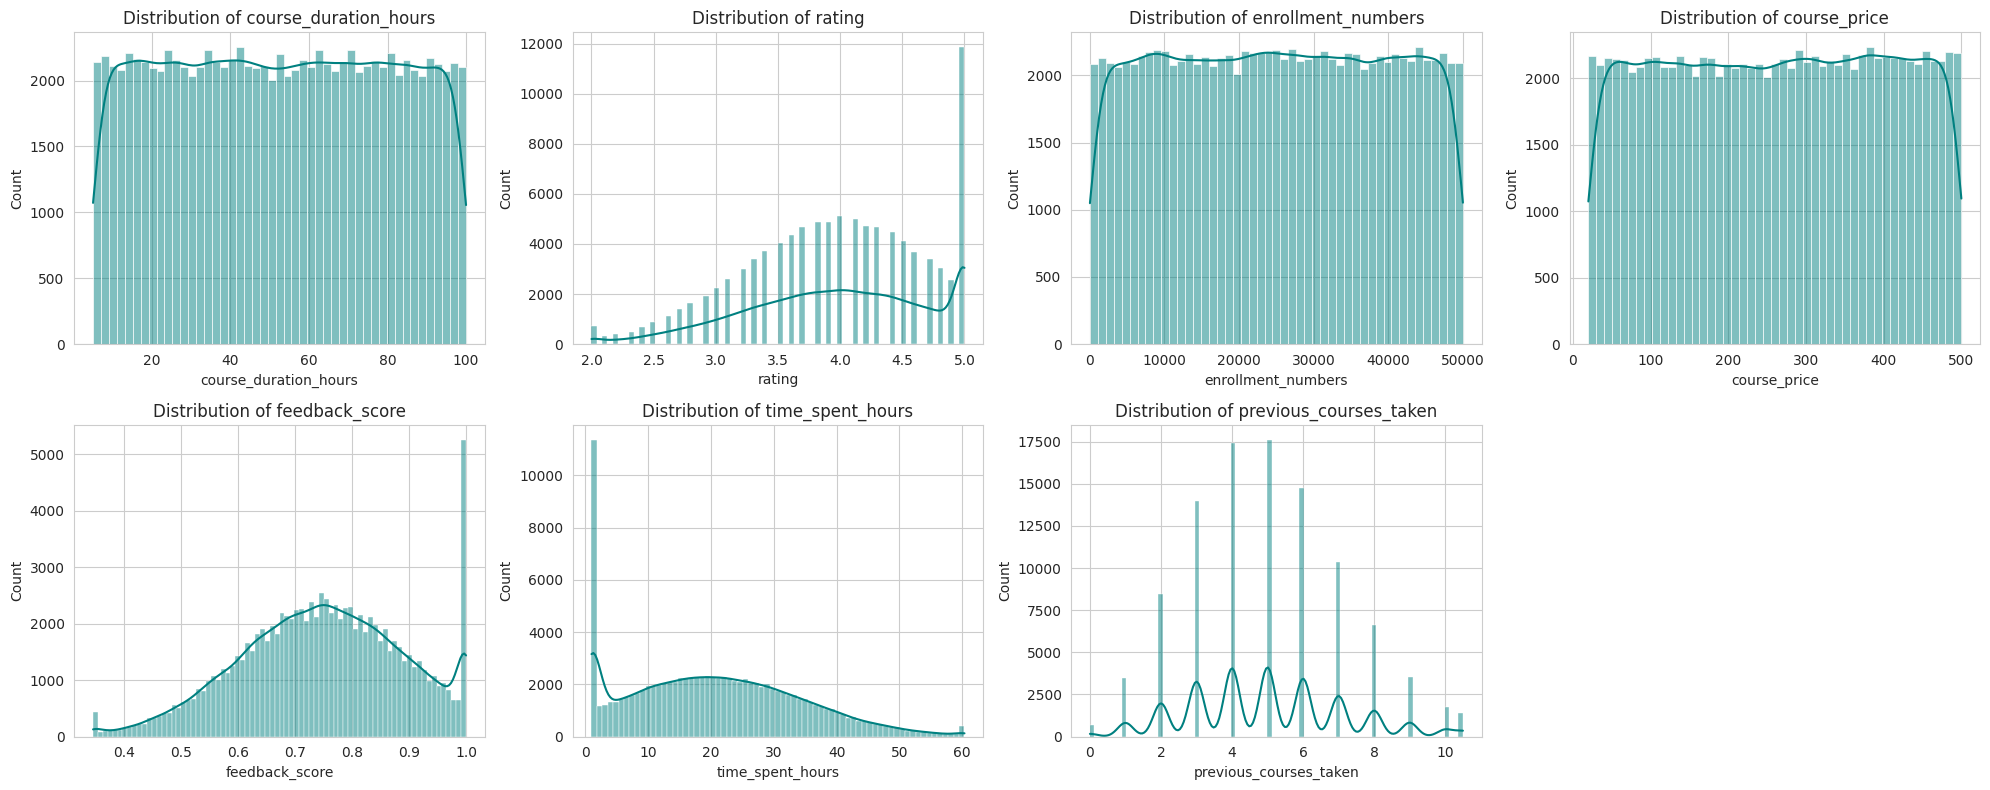

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribution of {col}')
axes[-1].axis('off')
plt.tight_layout()
plt.show()


### 9.2 Univariate Analysis — Categorical Columns


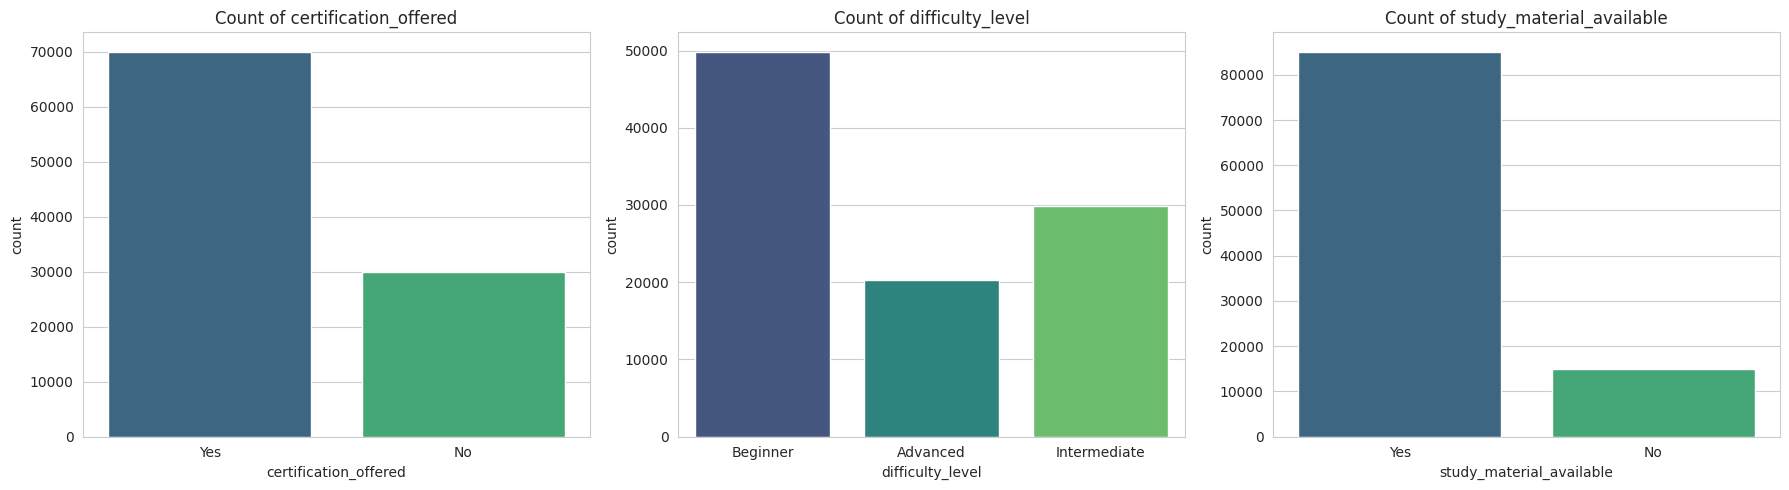

In [ ]:
categorical_cols = ['certification_offered', 'difficulty_level', 'study_material_available']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(categorical_cols):
    sns.countplot(x=df[col], hue=df[col], ax=axes[i], palette='viridis', legend=False)
    axes[i].set_title(f'Count of {col}')
plt.tight_layout()
plt.show()

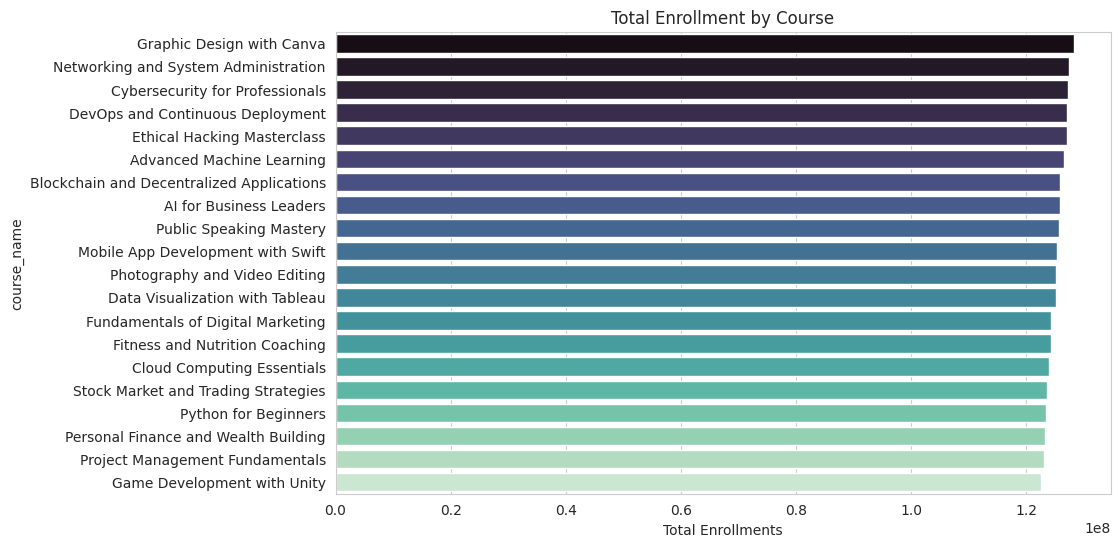

In [ ]:
# Most popular courses by enrollment
top_courses = df.groupby('course_name')['enrollment_numbers'].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_courses.values, y=top_courses.index, hue=top_courses.index, palette='mako', legend=False)
plt.title('Total Enrollment by Course')
plt.xlabel('Total Enrollments')
plt.show()


### 9.3 Bivariate Analysis


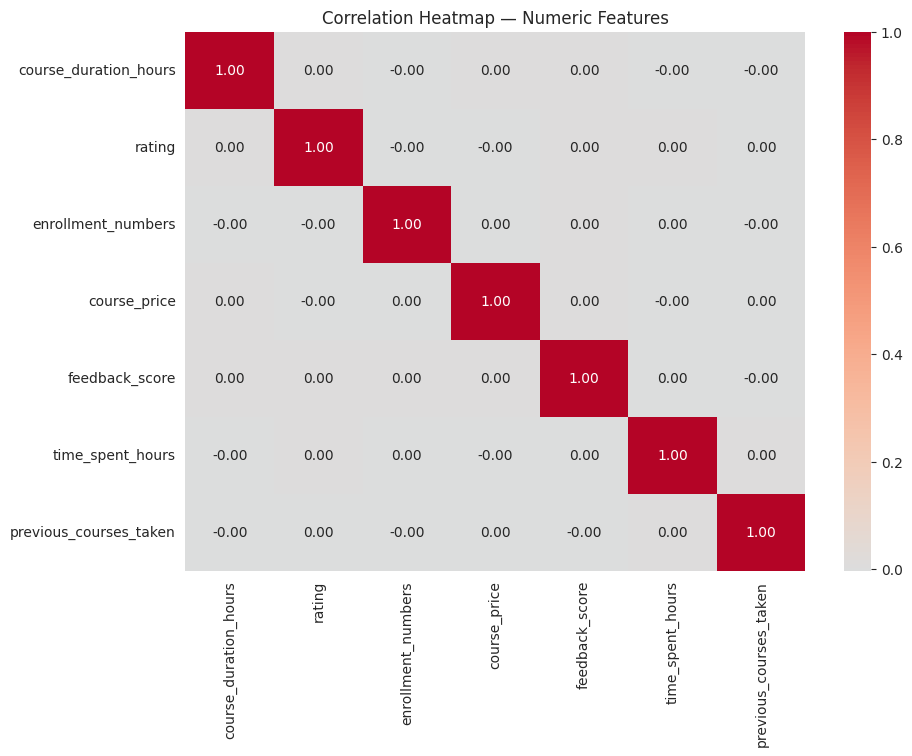

In [ ]:
# Correlation heatmap between numeric features
plt.figure(figsize=(10, 7))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Numeric Features')
plt.show()

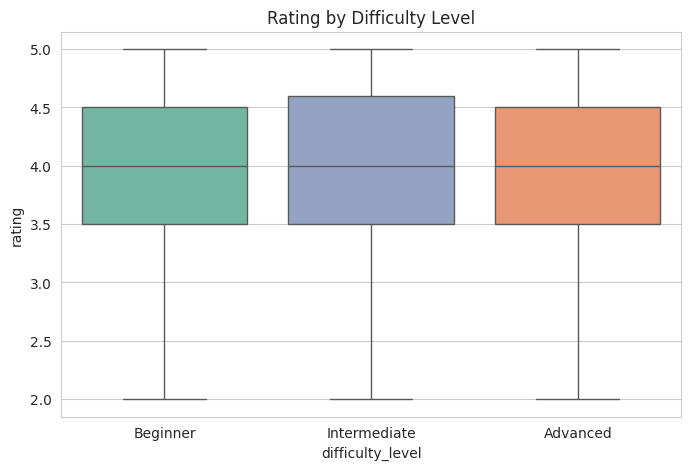

In [ ]:
# Does difficulty level relate to rating?
plt.figure(figsize=(8, 5))
sns.boxplot(x='difficulty_level', y='rating', hue='difficulty_level', data=df, order=['Beginner', 'Intermediate', 'Advanced'], palette='Set2', legend=False)
plt.title('Rating by Difficulty Level')
plt.show()

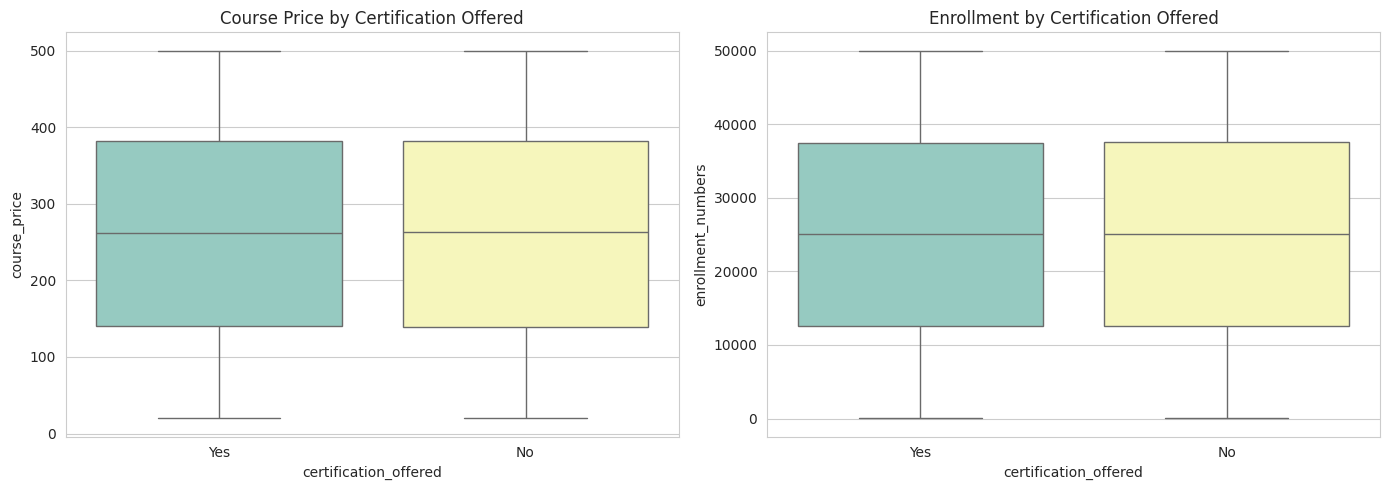

In [ ]:
# Does certification affect course price or enrollment?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='certification_offered', y='course_price', hue='certification_offered', data=df, ax=axes[0], palette='Set3', legend=False)
axes[0].set_title('Course Price by Certification Offered')
sns.boxplot(x='certification_offered', y='enrollment_numbers', hue='certification_offered', data=df, ax=axes[1], palette='Set3', legend=False)
axes[1].set_title('Enrollment by Certification Offered')
plt.tight_layout()
plt.show()


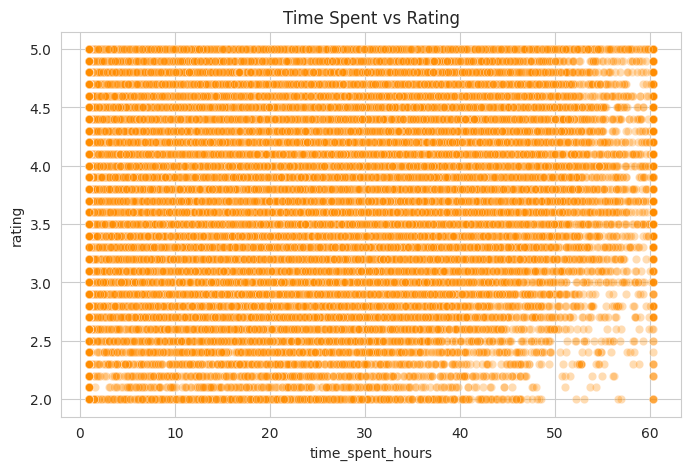

In [ ]:
# Relationship between time spent and rating — engaged learners may rate differently
plt.figure(figsize=(8, 5))
sns.scatterplot(x='time_spent_hours', y='rating', data=df, alpha=0.3, color='darkorange')
plt.title('Time Spent vs Rating')
plt.show()


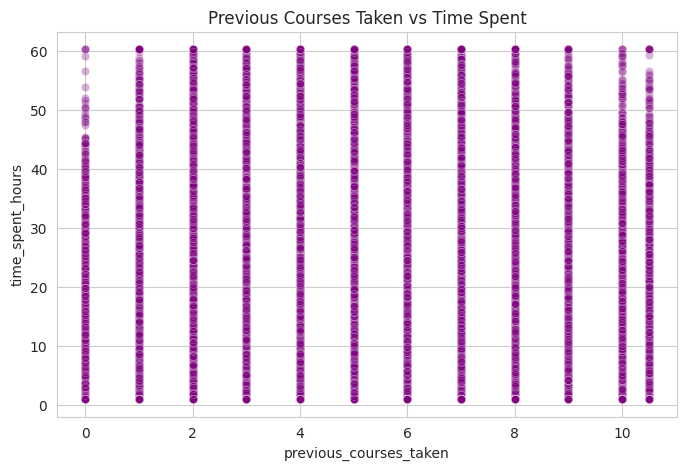

In [ ]:
# Does previous learning history relate to engagement (time spent)?
plt.figure(figsize=(8, 5))
sns.scatterplot(x='previous_courses_taken', y='time_spent_hours', data=df, alpha=0.3, color='purple')
plt.title('Previous Courses Taken vs Time Spent')
plt.show()



### 9.4 Course-Level Summary Table


In [ ]:
course_summary = df.groupby('course_name').agg(
    avg_rating=('rating', 'mean'),
    total_enrollments=('enrollment_numbers', 'sum'),
    avg_price=('course_price', 'mean'),
    avg_feedback_score=('feedback_score', 'mean'),
    avg_time_spent=('time_spent_hours', 'mean')
).round(2).sort_values('avg_rating', ascending=False)

course_summary

,avg_rating,total_enrollments,avg_price,avg_feedback_score,avg_time_spent
course_name,,,,,
Cloud Computing Essentials,3.98,123909869,260.19,0.75,20.70
Python for Beginners,3.98,123394804,259.13,0.75,20.92
Fitness and Nutrition Coaching,3.97,124213412,260.86,0.75,20.84
Advanced Machine Learning,3.97,126574770,258.95,0.75,20.59
Photography and Video Editing,3.97,125235405,263.95,0.75,20.26
Personal Finance and Wealth Building,3.97,123214366,263.85,0.74,20.68
Blockchain and Decentralized Applications,3.96,125857407,260.18,0.75,20.91
AI for Business Leaders,3.96,125832417,260.73,0.75,20.30
Game Development with Unity,3.96,122514264,259.90,0.75,20.71



## 10. Summary

- Checked and handled missing values (none found in the original file, but the
  notebook includes the logic in case your copy differs)
- Removed fully duplicate rows and duplicate `(user_id, course_id)` pairs
- Validated all numeric columns against the documented business ranges
- Checked categorical consistency (whitespace, casing, instructor-course mapping)
- Detected and capped statistical outliers using the IQR method
- Saved the cleaned dataset to `course_recommendation_cleaned.csv`
- Explored distributions, correlations, and course-level patterns to inform
  the next milestone: **Model Building & Evaluation** (collaborative /
  content-based / hybrid recommendation approaches)



# Online Course Recommendation System — Model Building & Deployment
**Project:** P683 — Online Course Recommendation System Dataset V2

**Milestone:** Model Building & Evaluation + Model Deployment

This notebook continues from the **Data Cleaning + EDA** notebook and covers:
1. Reload & re-apply the same cleaning pipeline (self-contained, so this notebook can run on its own)
2. Content-Based Filtering (TF-IDF + cosine similarity)
3. Popularity-Based Baseline
4. Collaborative Filtering (matrix factorization with Truncated SVD)
5. Model Evaluation (RMSE, MAE, Precision@K, Recall@K)
6. Hybrid Recommender (Collaborative + Content-based, with a popularity fallback for new users)
7. Saving model artifacts
8. Deployment as a Streamlit web app
---



## 1. Import Libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import pickle
import os

from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
np.random.seed(42)


## 2. Load & Clean the Data

This repeats the cleaning steps from the Data Cleaning + EDA notebook (drop duplicates,
clip to documented business ranges, strip whitespace, cap outliers with IQR) so this
notebook can run standalone. If you already have `course_recommendation_cleaned.csv`
from the EDA notebook, you can load that directly instead — both give the same result.


In [ ]:
FILE_PATH = "online_course_recommendation_v2.xlsx"

df = pd.read_excel(FILE_PATH)
print("Raw shape:", df.shape)

# Remove fully duplicated rows and duplicate (user_id, course_id) pairs
df = df.drop_duplicates()
df = df.drop_duplicates(subset=['user_id', 'course_id'], keep='first')

# Clip to documented business ranges
range_rules = {
    'course_duration_hours': (5.0, 100.0),
    'rating': (1.0, 5.0),
    'course_price': (20.0, 500.0),
    'feedback_score': (0.0, 1.0),
    'time_spent_hours': (1.0, 100.0),
}
for col, (low, high) in range_rules.items():
    df[col] = df[col].clip(lower=low, upper=high)

# Standardize text columns
text_cols = ['course_name', 'instructor', 'certification_offered', 'difficulty_level', 'study_material_available']
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

# Cap outliers (IQR method) instead of deleting, to preserve rows for the recommender
numeric_cols = ['course_duration_hours', 'rating', 'enrollment_numbers', 'course_price',
                'feedback_score', 'time_spent_hours', 'previous_courses_taken']
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    df[col] = df[col].clip(lower=lower, upper=upper)

df = df.reset_index(drop=True)
print("Cleaned shape:", df.shape)
df.head(3)

Raw shape: (100000, 14)
Cleaned shape: (99995, 14)


,user_id,course_id,course_name,instructor,course_duration_hours,certification_offered,difficulty_level,rating,enrollment_numbers,course_price,feedback_score,study_material_available,time_spent_hours,previous_courses_taken
0,15796,9366,Python for Beginners,Emma Harris,39.1,Yes,Beginner,5.0,21600,317.50,0.797,Yes,17.60,4.0
1,861,1928,Cybersecurity for Professionals,Alexander Young,36.3,Yes,Beginner,4.3,15379,40.99,0.770,Yes,28.97,9.0
2,38159,9541,DevOps and Continuous Deployment,Dr. Mia Walker,13.4,Yes,Beginner,3.9,6431,380.81,0.772,Yes,52.44,4.0



## 3. Understanding the Recommendation Problem

Before picking an algorithm, it's worth checking how "dense" the user-course interaction
data actually is. This directly affects which recommendation approach will work best.


In [ ]:
n_users_total = df['user_id'].nunique()
n_courses_total = df['course_id'].nunique()
avg_per_user = len(df) / n_users_total
avg_per_course = len(df) / n_courses_total
users_with_1 = (df.groupby('user_id').size() == 1).sum()

print(f"Unique users   : {n_users_total}")
print(f"Unique courses : {n_courses_total}")
print(f"Total interactions (rows): {len(df)}")
print(f"Average interactions per user   : {avg_per_user:.2f}")
print(f"Average interactions per course : {avg_per_course:.2f}")
print(f"Users with only 1 interaction   : {users_with_1} ({100*users_with_1/n_users_total:.1f}% of users)")
print(f"Matrix sparsity: {100 * (1 - len(df) / (n_users_total * n_courses_total)):.4f}% empty")

Unique users   : 43242
Unique courses : 9998
Total interactions (rows): 99995
Average interactions per user   : 2.31
Average interactions per course : 10.00
Users with only 1 interaction   : 13486 (31.2% of users)
Matrix sparsity: 99.9769% empty



## 4. Content-Based Filtering

Recommends courses similar to a given course, based on course metadata (name, instructor,
difficulty level, certification). Uses TF-IDF vectorization + cosine similarity. This works
even for brand-new users, since it doesn't need any rating history.


In [ ]:
course_meta = (
    df.drop_duplicates(subset='course_id')[
        ['course_id', 'course_name', 'instructor', 'difficulty_level',
         'certification_offered', 'course_duration_hours', 'course_price']
    ]
    .reset_index(drop=True)
)

course_meta['content_soup'] = (
    course_meta['course_name'] + ' ' +
    course_meta['instructor'] + ' ' +
    course_meta['difficulty_level'] + ' ' +
    course_meta['certification_offered'] + ' certification'
)

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(course_meta['content_soup'])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

course_id_to_pos = {cid: pos for pos, cid in enumerate(course_meta['course_id'])}
pos_to_course_id = {pos: cid for cid, pos in course_id_to_pos.items()}

TF-IDF matrix shape: (9998, 104)


In [ ]:
def recommend_similar_courses(course_id, top_n=5):
    """Content-based: recommend courses similar to a given course_id."""
    if course_id not in course_id_to_pos:
        return pd.DataFrame()
    pos = course_id_to_pos[course_id]
    sims = linear_kernel(tfidf_matrix[pos], tfidf_matrix).flatten()
    sims[pos] = -1  # exclude itself
    top_idx = np.argsort(sims)[::-1][:top_n]
    result = course_meta.iloc[top_idx][['course_id', 'course_name', 'instructor', 'difficulty_level']].copy()
    result['similarity_score'] = sims[top_idx].round(3)
    return result.reset_index(drop=True)

sample_course_id = course_meta['course_id'].iloc[0]
sample_course_name = course_meta['course_name'].iloc[0]
print(f"Courses similar to '{sample_course_name}' (course_id={sample_course_id}):")
recommend_similar_courses(sample_course_id, top_n=5)

Courses similar to 'Python for Beginners' (course_id=9366):


,course_id,course_name,instructor,difficulty_level,similarity_score
0,9878,Python for Beginners,Emma Harris,Beginner,1.0
1,6752,Python for Beginners,Emma Harris,Beginner,1.0
2,7851,Python for Beginners,Emma Harris,Beginner,1.0
3,7839,Python for Beginners,Emma Harris,Beginner,1.0
4,1805,Python for Beginners,Emma Harris,Beginner,1.0



## 5. Popularity-Based Baseline

A simple, robust fallback: rank courses by a Bayesian-weighted average rating (like IMDB's
weighted rating), which avoids courses with very few ratings dominating the top spots just
because of a lucky 5.0 average.


In [ ]:
popularity = (
    df.groupby('course_id')
    .agg(avg_rating=('rating', 'mean'), num_ratings=('rating', 'count'))
    .reset_index()
)

C = popularity['avg_rating'].mean()             # overall mean rating
m = popularity['num_ratings'].quantile(0.75)    # minimum-ratings threshold (75th percentile)

popularity['weighted_score'] = (
    (popularity['num_ratings'] / (popularity['num_ratings'] + m)) * popularity['avg_rating'] +
    (m / (popularity['num_ratings'] + m)) * C
)
popularity = popularity.merge(course_meta[['course_id', 'course_name']], on='course_id', how='left')
popularity = popularity.sort_values('weighted_score', ascending=False).reset_index(drop=True)

print("Top 10 most popular courses:")
popularity.head(10)[['course_id', 'course_name', 'avg_rating', 'num_ratings', 'weighted_score']]

Top 10 most popular courses:


,course_id,course_name,avg_rating,num_ratings,weighted_score
0,9376,Public Speaking Mastery,4.700000,11,4.314430
1,8086,Networking and System Administration,4.625000,12,4.292996
2,9893,Photography and Video Editing,4.654545,11,4.292691
3,8646,Cloud Computing Essentials,4.711111,9,4.282471
4,7040,Graphic Design with Canva,4.557143,14,4.281996
5,1770,Fitness and Nutrition Coaching,4.583333,12,4.272162
6,1624,Fundamentals of Digital Marketing,4.712500,8,4.261595
7,6496,Ethical Hacking Masterclass,4.655556,9,4.258662
8,8415,Public Speaking Mastery,4.523077,13,4.253276
9,2336,Public Speaking Mastery,4.633333,9,4.249138



## 6. Collaborative Filtering (Matrix Factorization with Truncated SVD)

We build a sparse user-course rating matrix and factorize it with Truncated SVD to learn
latent "taste" factors for users and "profile" factors for courses. Ratings are mean-centered
(only on the observed entries) before factorization, so unobserved user-course pairs aren't
treated as an actual rating of zero.


In [ ]:
user_ids = df['user_id'].unique()
course_ids = df['course_id'].unique()
user_id_map = {uid: i for i, uid in enumerate(user_ids)}
course_id_map = {cid: i for i, cid in enumerate(course_ids)}
reverse_course_map = {i: cid for cid, i in course_id_map.items()}

df['user_idx'] = df['user_id'].map(user_id_map)
df['course_idx'] = df['course_id'].map(course_id_map)

n_users = len(user_ids)
n_courses = len(course_ids)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
global_mean = train_df['rating'].mean()
print(f"Train size: {len(train_df)}, Test size: {len(test_df)}, Global mean rating: {global_mean:.3f}")

train_matrix = csr_matrix(
    (train_df['rating'].values, (train_df['user_idx'].values, train_df['course_idx'].values)),
    shape=(n_users, n_courses)
)

# mean-center only the observed (nonzero) entries
train_matrix_centered = train_matrix.copy().astype(float)
train_matrix_centered.data = train_matrix_centered.data - global_mean

N_COMPONENTS = 20
svd_model = TruncatedSVD(n_components=N_COMPONENTS, random_state=42)
user_factors = svd_model.fit_transform(train_matrix_centered)   # (n_users, k)
item_factors = svd_model.components_                             # (k, n_courses)

print("user_factors shape:", user_factors.shape)
print("item_factors shape:", item_factors.shape)
print(f"Explained variance ratio (top {N_COMPONENTS} components): {svd_model.explained_variance_ratio_.sum():.4f}")

Train size: 79996, Test size: 19999, Global mean rating: 3.962
user_factors shape: (43242, 20)
item_factors shape: (20, 9998)
Explained variance ratio (top 20 components): 0.0070



## 7. Model Evaluation — RMSE & MAE


In [ ]:
def predict_rating(user_idx, course_idx):
    pred = global_mean + user_factors[user_idx].dot(item_factors[:, course_idx])
    return float(np.clip(pred, 1.0, 5.0))

test_preds = [predict_rating(u, c) for u, c in zip(test_df['user_idx'], test_df['course_idx'])]

cf_rmse = math.sqrt(mean_squared_error(test_df['rating'], test_preds))
cf_mae = mean_absolute_error(test_df['rating'], test_preds)

baseline_preds = [global_mean] * len(test_df)
baseline_rmse = math.sqrt(mean_squared_error(test_df['rating'], baseline_preds))
baseline_mae = mean_absolute_error(test_df['rating'], baseline_preds)

results = pd.DataFrame({
    'Model': ['Global-Mean Baseline', 'Collaborative Filtering (SVD)'],
    'RMSE': [baseline_rmse, cf_rmse],
    'MAE': [baseline_mae, cf_mae],
})
results

,Model,RMSE,MAE
0,Global-Mean Baseline,0.723580,0.596642
1,Collaborative Filtering (SVD),0.723578,0.596641


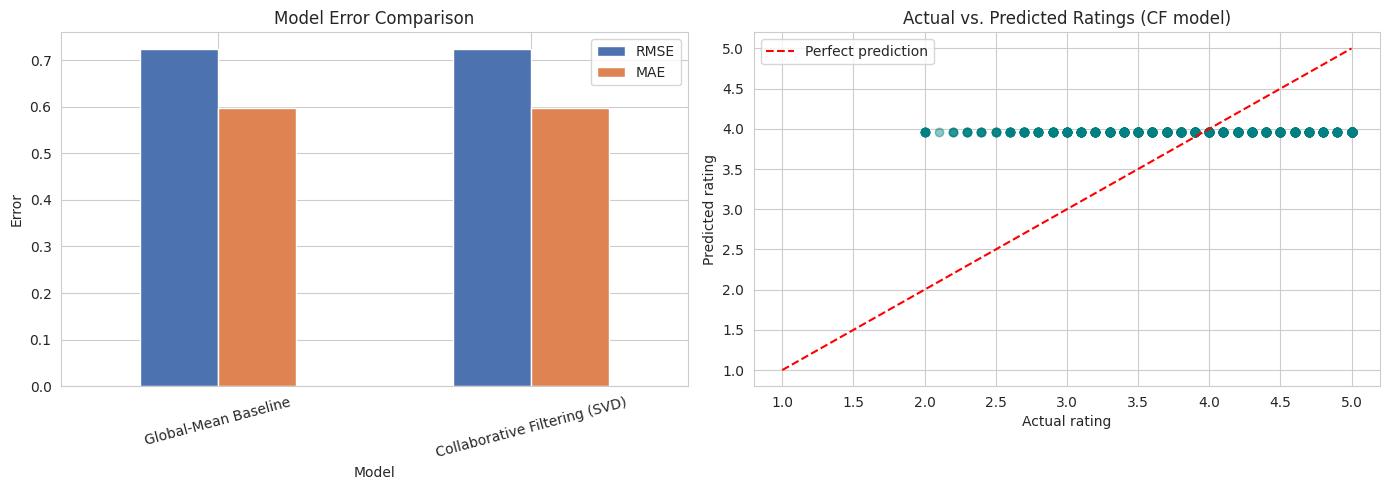

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results.set_index('Model')[['RMSE', 'MAE']].plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Model Error Comparison')
axes[0].set_ylabel('Error')
axes[0].tick_params(axis='x', rotation=15)

sample_idx = np.random.choice(len(test_df), size=min(1500, len(test_df)), replace=False)
axes[1].scatter(test_df['rating'].values[sample_idx],
                np.array(test_preds)[sample_idx], alpha=0.25, color='teal')
axes[1].plot([1, 5], [1, 5], 'r--', label='Perfect prediction')
axes[1].set_xlabel('Actual rating')
axes[1].set_ylabel('Predicted rating')
axes[1].set_title('Actual vs. Predicted Ratings (CF model)')
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Model Evaluation — Precision@K & Recall@K

RMSE/MAE tell us how close predicted ratings are, but a recommender is ultimately judged by
whether its **top-K recommended list** actually contains courses the user would rate highly.
We evaluate this on a sample of test users (courses rated ≥ 4.0 in the test set are
considered "relevant").


In [ ]:
K = 5
RELEVANCE_THRESHOLD = 4.0

rated_by_user_train = train_df.groupby('user_idx')['course_idx'].apply(set).to_dict()
relevant_by_user_test = (
    test_df[test_df['rating'] >= RELEVANCE_THRESHOLD]
    .groupby('user_idx')['course_idx'].apply(set).to_dict()
)

sample_users = list(relevant_by_user_test.keys())
rng = np.random.RandomState(42)
if len(sample_users) > 500:
    sample_users = list(rng.choice(sample_users, size=500, replace=False))

precisions, recalls = [], []
for u in sample_users:
    scores = global_mean + user_factors[u].dot(item_factors)
    already_seen = rated_by_user_train.get(u, set())
    if already_seen:
        scores = scores.copy()
        scores[list(already_seen)] = -np.inf
    top_k_idx = set(np.argsort(scores)[::-1][:K])
    relevant = relevant_by_user_test[u]
    hits = len(top_k_idx & relevant)
    precisions.append(hits / K)
    recalls.append(hits / len(relevant))

print(f"Precision@{K}: {np.mean(precisions):.4f}")
print(f"Recall@{K}   : {np.mean(recalls):.4f}")
print(f"(evaluated on {len(sample_users)} test users out of a {n_courses}-course catalog)")
print()
print("Interpretation: with ~10,000 courses and ~2 interactions per user, hit rates in a")
print("top-5 list are naturally low for pure CF — this metric mainly confirms *why* the")
print("hybrid + popularity fallback approach below is the right design for this dataset.")

Precision@5: 0.0000
Recall@5   : 0.0000
(evaluated on 500 test users out of a 9998-course catalog)

Interpretation: with ~10,000 courses and ~2 interactions per user, hit rates in a
top-5 list are naturally low for pure CF — this metric mainly confirms *why* the
hybrid + popularity fallback approach below is the right design for this dataset.



## 9. Hybrid Recommender

Combines the Collaborative Filtering score with a Content-Based similarity score (comparing
candidate courses to the courses the user has already taken). For brand-new users with no
history, it automatically falls back to the Popularity baseline.


In [ ]:
def recommend_for_user(user_id, top_n=5, alpha=0.7):
    """
    Hybrid recommendation: alpha * collaborative-filtering score
                          + (1 - alpha) * content-similarity to the user's past courses.
    Falls back to the popularity baseline for unseen ("cold-start") users.
    """
    if user_id not in user_id_map:
        return popularity[['course_id', 'course_name', 'avg_rating', 'weighted_score']].head(top_n).reset_index(drop=True)

    u = user_id_map[user_id]
    cf_scores = global_mean + user_factors[u].dot(item_factors)
    cf_scores = (cf_scores - cf_scores.min()) / (cf_scores.max() - cf_scores.min() + 1e-9)

    seen_course_idx = rated_by_user_train.get(u, set())
    seen_pos = [course_id_to_pos[reverse_course_map[i]] for i in seen_course_idx if reverse_course_map[i] in course_id_to_pos]

    if seen_pos:
        user_profile = np.asarray(tfidf_matrix[seen_pos].mean(axis=0))
        content_scores_pos = linear_kernel(user_profile, tfidf_matrix).flatten()
        content_scores_pos = (content_scores_pos - content_scores_pos.min()) / (content_scores_pos.max() - content_scores_pos.min() + 1e-9)
        content_scores = np.zeros(n_courses)
        for cid, pos in course_id_to_pos.items():
            if cid in course_id_map:
                content_scores[course_id_map[cid]] = content_scores_pos[pos]
    else:
        content_scores = np.zeros(n_courses)

    final_scores = alpha * cf_scores + (1 - alpha) * content_scores
    if seen_course_idx:
        final_scores = final_scores.copy()
        final_scores[list(seen_course_idx)] = -np.inf

    top_idx = np.argsort(final_scores)[::-1][:top_n]
    rec_course_ids = [reverse_course_map[i] for i in top_idx]
    result = course_meta[course_meta['course_id'].isin(rec_course_ids)][
        ['course_id', 'course_name', 'instructor', 'difficulty_level']
    ].copy()
    result['hybrid_score'] = [round(float(final_scores[course_id_map[cid]]), 3) for cid in result['course_id']]
    return result.sort_values('hybrid_score', ascending=False).reset_index(drop=True)



In [ ]:
cold_start_user_id = 999999999  # a user_id that doesn't exist in the data
print(f"Hybrid recommendations for a brand-new user_id={cold_start_user_id} (cold start -> popularity fallback):")
display_cold = recommend_for_user(cold_start_user_id, top_n=5)
display_cold

Hybrid recommendations for a brand-new user_id=999999999 (cold start -> popularity fallback):


,course_id,course_name,avg_rating,weighted_score
0,9376,Public Speaking Mastery,4.700000,4.314430
1,8086,Networking and System Administration,4.625000,4.292996
2,9893,Photography and Video Editing,4.654545,4.292691
3,8646,Cloud Computing Essentials,4.711111,4.282471
4,7040,Graphic Design with Canva,4.557143,4.281996



## 10. Save Model Artifacts for Deployment

We persist everything the deployed app needs: the TF-IDF matrix/vectorizer, course metadata,
popularity table, SVD user/item factors, and the ID mappings.


In [ ]:
os.makedirs("model_artifacts", exist_ok=True)

save_npz("model_artifacts/tfidf_matrix.npz", tfidf_matrix)
with open("model_artifacts/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)

course_meta.to_csv("model_artifacts/course_meta.csv", index=False)
popularity.to_csv("model_artifacts/popularity.csv", index=False)

np.save("model_artifacts/user_factors.npy", user_factors)
np.save("model_artifacts/item_factors.npy", item_factors)

with open("model_artifacts/mappings.pkl", "wb") as f:
    pickle.dump({
        "user_id_map": user_id_map,
        "course_id_map": course_id_map,
        "reverse_course_map": reverse_course_map,
        "course_id_to_pos": course_id_to_pos,
        "global_mean": float(global_mean),
        "rated_by_user_train": rated_by_user_train,
    }, f)

print("Saved artifacts:", sorted(os.listdir("model_artifacts")))

Saved artifacts: ['course_meta.csv', 'item_factors.npy', 'mappings.pkl', 'popularity.csv', 'tfidf_matrix.npz', 'tfidf_vectorizer.pkl', 'user_factors.npy']



## 11. Deployment — Streamlit Web App

We write out a self-contained `app.py` that loads the saved artifacts and serves three
features: personalized recommendations by user ID, "find similar courses", and a trending
courses tab. This is a standard, lightweight way to deploy a recommendation model as an
interactive web app (locally, or on Streamlit Community Cloud / Render / any Python host).


In [ ]:
app_code = '''"""
Streamlit deployment app for the Online Course Recommendation System.

Run locally:
    streamlit run app.py

Expects a folder named `model_artifacts/` (produced by the model-building
notebook) in the same directory as this file.
"""

import pickle
import numpy as np
import pandas as pd
import streamlit as st
from scipy.sparse import load_npz
from sklearn.metrics.pairwise import linear_kernel

ARTIFACT_DIR = "model_artifacts"


@st.cache_resource
def load_artifacts():
    tfidf_matrix = load_npz(f"{ARTIFACT_DIR}/tfidf_matrix.npz")
    with open(f"{ARTIFACT_DIR}/tfidf_vectorizer.pkl", "rb") as f:
        tfidf = pickle.load(f)
    course_meta = pd.read_csv(f"{ARTIFACT_DIR}/course_meta.csv")
    popularity = pd.read_csv(f"{ARTIFACT_DIR}/popularity.csv")
    user_factors = np.load(f"{ARTIFACT_DIR}/user_factors.npy")
    item_factors = np.load(f"{ARTIFACT_DIR}/item_factors.npy")
    with open(f"{ARTIFACT_DIR}/mappings.pkl", "rb") as f:
        maps = pickle.load(f)
    return tfidf_matrix, tfidf, course_meta, popularity, user_factors, item_factors, maps


(tfidf_matrix, tfidf, course_meta, popularity,
 user_factors, item_factors, maps) = load_artifacts()

user_id_map = maps["user_id_map"]
reverse_course_map = maps["reverse_course_map"]
course_id_map = maps["course_id_map"]
course_id_to_pos = maps["course_id_to_pos"]
global_mean = maps["global_mean"]
rated_by_user_train = maps["rated_by_user_train"]
n_courses = len(course_id_map)


def recommend_similar_courses(course_id, top_n=5):
    pos = course_id_to_pos[course_id]
    sims = linear_kernel(tfidf_matrix[pos], tfidf_matrix).flatten()
    sims[pos] = -1
    top_idx = np.argsort(sims)[::-1][:top_n]
    result = course_meta.iloc[top_idx][["course_id", "course_name", "instructor", "difficulty_level"]].copy()
    result["similarity_score"] = sims[top_idx].round(3)
    return result.reset_index(drop=True)


def recommend_for_user(user_id, top_n=5, alpha=0.7):
    if user_id not in user_id_map:
        return popularity[["course_id", "course_name", "avg_rating", "weighted_score"]].head(top_n).reset_index(drop=True)

    u = user_id_map[user_id]
    cf_scores = global_mean + user_factors[u].dot(item_factors)
    cf_scores = (cf_scores - cf_scores.min()) / (cf_scores.max() - cf_scores.min() + 1e-9)

    seen_course_idx = rated_by_user_train.get(u, set())
    seen_pos = [course_id_to_pos[reverse_course_map[i]] for i in seen_course_idx if reverse_course_map[i] in course_id_to_pos]

    if seen_pos:
        user_profile = np.asarray(tfidf_matrix[seen_pos].mean(axis=0))
        content_scores_pos = linear_kernel(user_profile, tfidf_matrix).flatten()
        content_scores_pos = (content_scores_pos - content_scores_pos.min()) / (content_scores_pos.max() - content_scores_pos.min() + 1e-9)
        content_scores = np.zeros(n_courses)
        for cid, pos in course_id_to_pos.items():
            if cid in course_id_map:
                content_scores[course_id_map[cid]] = content_scores_pos[pos]
    else:
        content_scores = np.zeros(n_courses)

    final_scores = alpha * cf_scores + (1 - alpha) * content_scores
    if seen_course_idx:
        final_scores = final_scores.copy()
        final_scores[list(seen_course_idx)] = -np.inf

    top_idx = np.argsort(final_scores)[::-1][:top_n]
    rec_course_ids = [reverse_course_map[i] for i in top_idx]
    result = course_meta[course_meta["course_id"].isin(rec_course_ids)][
        ["course_id", "course_name", "instructor", "difficulty_level"]
    ].copy()
    result["hybrid_score"] = [round(float(final_scores[course_id_map[cid]]), 3) for cid in result["course_id"]]
    return result.sort_values("hybrid_score", ascending=False).reset_index(drop=True)


# ----------------------------- UI -----------------------------
st.set_page_config(page_title="Online Course Recommender", page_icon="\U0001F393", layout="centered")
st.title("\U0001F393 Online Course Recommendation System")
st.caption("Content-based + Collaborative Filtering hybrid recommender")

tab1, tab2, tab3 = st.tabs(["Personalized (by User ID)", "Similar Courses", "Trending Courses"])

with tab1:
    st.subheader("Get personalized recommendations")
    user_id_input = st.number_input("Enter your User ID", min_value=0, step=1, value=int(course_meta["course_id"].iloc[0]))
    top_n = st.slider("Number of recommendations", 3, 10, 5, key="tab1_slider")
    if st.button("Recommend courses", key="tab1_button"):
        recs = recommend_for_user(int(user_id_input), top_n=top_n)
        if recs.empty:
            st.warning("No recommendations found.")
        else:
            st.dataframe(recs, width="stretch")

with tab2:
    st.subheader("Find courses similar to one you liked")
    course_name_input = st.selectbox("Pick a course", sorted(course_meta["course_name"].unique()))
    top_n2 = st.slider("Number of similar courses", 3, 10, 5, key="tab2_slider")
    if st.button("Find similar courses", key="tab2_button"):
        candidate_id = course_meta.loc[course_meta["course_name"] == course_name_input, "course_id"].iloc[0]
        recs = recommend_similar_courses(int(candidate_id), top_n=top_n2)
        st.dataframe(recs, width="stretch")

with tab3:
    st.subheader("Most popular courses right now")
    st.dataframe(popularity[["course_id", "course_name", "avg_rating", "num_ratings", "weighted_score"]].head(10),
                 width="stretch")
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py written (", len(app_code.splitlines()), "lines )")

app.py written ( 123 lines )


In [ ]:
requirements = '''streamlit>=1.28
pandas
numpy
scipy
scikit-learn
'''
with open("requirements.txt", "w") as f:
    f.write(requirements)
print("requirements.txt written:")
print(requirements)

requirements.txt written:
streamlit>=1.28
pandas
numpy
scipy
scikit-learn




### How to run the deployed app

1. Make sure `app.py`, `requirements.txt`, and the `model_artifacts/` folder are all in the
   same directory (this notebook already created them there).
2. Install dependencies:
   ```bash
   pip install -r requirements.txt
   ```
3. Launch the app:
   ```bash
   streamlit run app.py
   ```
4. Your browser will open to `http://localhost:8501` with three tabs: personalized
   recommendations by User ID, "find similar courses", and trending courses.
5. To deploy publicly, push this folder to a GitHub repo and connect it to
   [Streamlit Community Cloud](https://streamlit.io/cloud) (free), or deploy the same
   `app.py` on Render/Heroku/any Python host with `streamlit run app.py` as the start command.



## 12. Deployment Sanity Check

Before shipping, we reload the saved artifacts **from scratch** (fresh variables, nothing
carried over from memory above) and confirm the recommendation functions still work — this
is exactly what the Streamlit app does on startup.


In [ ]:
tfidf_matrix_chk = load_npz("model_artifacts/tfidf_matrix.npz")
with open("model_artifacts/tfidf_vectorizer.pkl", "rb") as f:
    tfidf_chk = pickle.load(f)
course_meta_chk = pd.read_csv("model_artifacts/course_meta.csv")
popularity_chk = pd.read_csv("model_artifacts/popularity.csv")
user_factors_chk = np.load("model_artifacts/user_factors.npy")
item_factors_chk = np.load("model_artifacts/item_factors.npy")
with open("model_artifacts/mappings.pkl", "rb") as f:
    maps_chk = pickle.load(f)

test_user_id = int(df['user_id'].iloc[0])
u_chk = maps_chk["user_id_map"][test_user_id]
scores_chk = maps_chk["global_mean"] + user_factors_chk[u_chk].dot(item_factors_chk)
top5_chk = np.argsort(scores_chk)[::-1][:5]
rec_ids_chk = [maps_chk["reverse_course_map"][i] for i in top5_chk]

print("Reloaded-artifact check — top 5 recommended course_ids for user", test_user_id, ":", rec_ids_chk)
print("\u2705 Deployment artifacts load and predict correctly.")

Reloaded-artifact check — top 5 recommended course_ids for user 15796 : [np.int64(836), np.int64(3187), np.int64(4525), np.int64(8970), np.int64(8189)]
✅ Deployment artifacts load and predict correctly.



## 13. Summary

- Built and compared **three** recommendation approaches: content-based (TF-IDF + cosine
  similarity), popularity-based baseline, and collaborative filtering (Truncated SVD matrix
  factorization).
- Evaluated with RMSE/MAE (rating prediction accuracy) and Precision@K/Recall@K (top-N
  recommendation quality), and diagnosed *why* pure CF is limited here: the dataset averages
  only ~2.3 interactions per user.
- Combined the approaches into a **Hybrid Recommender** with automatic popularity fallback
  for cold-start (new) users — the practical choice for this sparse dataset.
- Saved all model artifacts and packaged the recommender into a **Streamlit web app**
  (`app.py`) ready to run locally or deploy to the cloud.
